# Machine Learning 2 - Neural Networks

In this lab, we will use simple Neural Networks to classify the images from the simplified CIFAR-10 dataset. We will compare our results with those obtained with Decision Trees and Random Forests.

Lab objectives
----
* Classification with neural networks
* Influence of hidden layers and of the selected features on the classifier results

In [2]:
from lab_tools import CIFAR10, evaluate_classifier, get_hog_image
        
dataset = CIFAR10('CIFAR10/')

Pre-loading training data
Pre-loading test data


We will use the *[Multi-Layer Perceptron](http://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html#sklearn.neural_network.MLPClassifier)* implementation from scikit-learn, which is only available since version 0.18. You can check which version of scikit-learn is installed by executing this :

In [3]:
import sklearn
print(sklearn.__version__)

1.8.0


If you have version 0.17 or older, please update your scikit-learn installation (for instance, with the command *pip install scikit-learn==0.19.1* in the terminal or Anaconda prompt)

## Build a simple neural network

* Using the [MLPClassifier](http://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) from scikit-learn, create a neural network with a single hidden layer.
* Train this network on the CIFAR dataset.
* Using cross-validation, try to find the best possible parameters.

In [ ]:
from sklearn.neural_network import MLPClassifier
from matplotlib import pyplot as plt
from sklearn.model_selection import cross_val_score
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score

In [ ]:
kf = StratifiedKFold(8)

cms = []
accs = []

for train,test in kf.split(dataset.train['hog'], dataset.train['labels']):
    train_x = dataset.train['hog'][train]
    train_y = dataset.train['labels'][train]

    clf = MLPClassifier(hidden_layer_sizes=(25,), learning_rate_init=0.01, verbose=False, early_stopping=True)
    clf.fit(train_x, train_y)
    
    test_x = dataset.train['hog'][test]
    test_y = dataset.train['labels'][test]
    pred = clf.predict(test_x)
    cms.append(confusion_matrix(test_y, pred))
    accs.append(accuracy_score(test_y, pred))

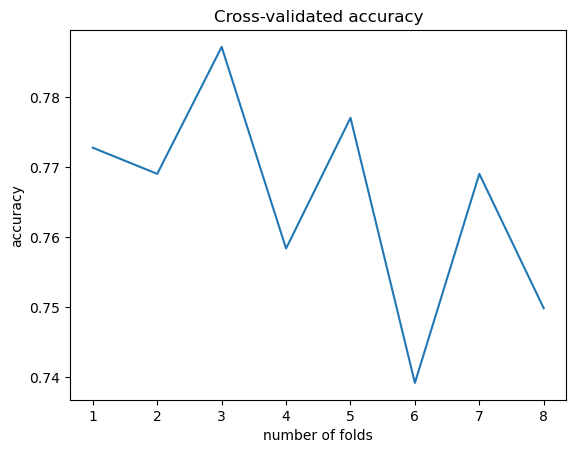

In [6]:
fig, ax = plt.subplots()
ax.plot(range(1,9), accs)
ax.set_xlabel("number of folds")
#ax.set_xscale("log")
plt.ylabel("accuracy")
plt.title("Cross-validated accuracy")
plt.show()

[0.7728, 0.7690666666666667, 0.7872, 0.7584, 0.7770666666666667, 0.7392, 0.7690666666666667, 0.7498666666666667]


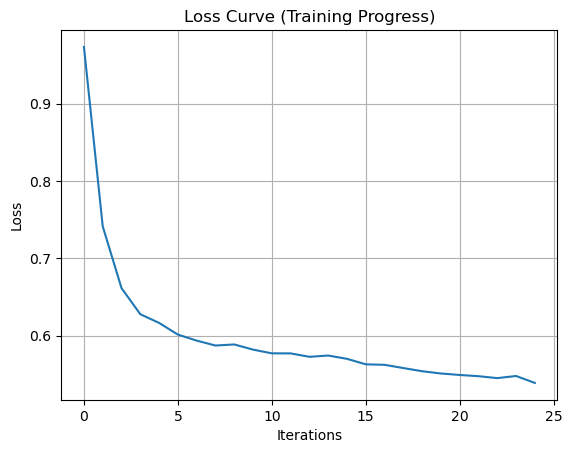

In [7]:
import matplotlib.pyplot as plt

print(accs)
plt.plot(clf.loss_curve_)
plt.title("Loss Curve (Training Progress)")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid()
plt.show()

# loss curve describe that it's getting better at the training set
# so can be different if you want to predict something

## Add hidden layers to the network.

Try to change the structure of the network by adding hidden layers. Using cross-validation, try to find the best architecture for your network.

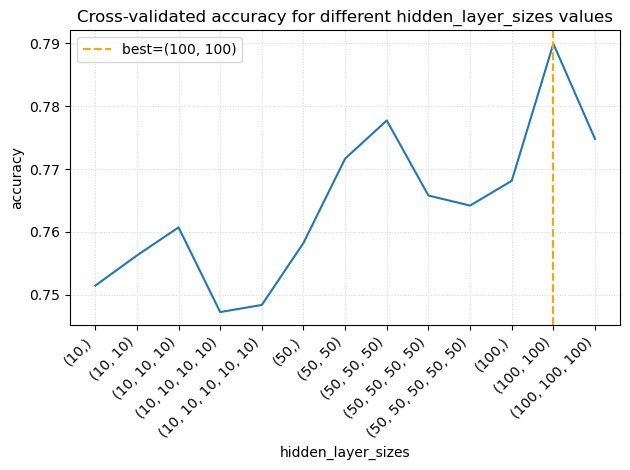

Best hidden_layer_sizes: (100, 100)


In [ ]:
hidden_layer_sizes = [
    (10,), (10, 10), (10, 10, 10), (10, 10, 10, 10), (10, 10, 10, 10, 10),
    (50,), (50, 50), (50, 50, 50), (50, 50, 50, 50), (50, 50, 50, 50, 50),
    (100,), (100, 100), (100, 100, 100),
]   


acc_score = []

for i in hidden_layer_sizes:
    clf = MLPClassifier(
        hidden_layer_sizes=i,
        random_state=2026,
        verbose=False,
        max_iter=1000,
        early_stopping=True,
        tol=0.002,
        n_iter_no_change=50,
    )
    scores = cross_val_score(clf, dataset.train['hog'], dataset.train['labels'],n_jobs=-1).mean()
    acc_score.append(scores) # we need to use the mean because a fold impose to get not one score but multiple score


best_idx = np.argmax(acc_score)
print("Best hidden_layer_sizes:", hidden_layer_sizes[best_idx])


In [ ]:
fig, ax = plt.subplots()

x = range(len(hidden_layer_sizes))
ax.plot(x, acc_score)

# Etichette con le tuple
ax.set_xticks(x)
ax.set_xticklabels([str(h) for h in hidden_layer_sizes], rotation=45, ha='right')

ax.axvline(best_idx, color='orange', linestyle='--', label=f'best={hidden_layer_sizes[best_idx]}')

ax.set_xlabel("hidden_layer_sizes")
ax.set_ylabel("accuracy")
ax.set_title("Cross-validated accuracy for different hidden_layer_sizes values")
ax.legend()
ax.grid(True, linestyle=':', alpha=0.5, linewidth=0.7)

plt.tight_layout()
fig.savefig("figures/cross_val_mlp.pdf", bbox_inches="tight")
plt.show()